## Validation of the filtered Lausanne population against the Microcensus (MZ 2015)
Focus: population structure, activity chains and destinations (filtered data, households living in the study area).

Population definition:
   * Simulation: every agent of the filtered MATSim population, aged `MIN_AGE` or older. Every agent counts equally (weight 1).
   * Microcensus: every target person living in a household inside the study area (`household_ids_in_area.csv`), aged `MIN_AGE` or older, weighted with the MZ person weight (households: `WM`). Population-structure comparisons use all survey days, trip-based comparisons (chains, destinations) weekdays only.

All figures and tables are written to the `results` folder next to this notebook. In all bar charts the simulation is drawn solid and the Microcensus hatched.

### Preparatory Imports

In [1]:
from pathlib import Path
import csv
import gzip
import re
import xml.etree.ElementTree as ET
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter

import geopandas as gpd
import shapely
import contextily as ctx

In [2]:
# File Paths
# Relative paths are relative to the folder the notebook runs from (= the folder of this file in Jupyter / VS Code)
NOTEBOOK_DIR = Path.cwd()
OUT_DIR = NOTEBOOK_DIR / 'results'
OUT_DIR.mkdir(parents=True, exist_ok=True)

NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = NOTEBOOK_DIR.parent  # go up one level to ass_2

# MATSIM_POP_FILE = Path('working_rep/filterred_data/lausanne_population_filtered.xml.gz')
# MATSIM_HH_FILE  = Path('working_rep/filterred_data/lausanne_households_filtered.xml.gz')
# HH_IDS_FILE     = Path('working_rep/filterred_data/mz/household_ids_in_area.csv')   # MZ households living in the study area
# MZ_DIR          = Path('Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus')
# BOUNDARY_FILE   = Path(r'C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\Lausanne_10pct\Lausanne_10pct\Boundary\LausanneExtent.shp')

# File Paths
MATSIM_POP_FILE = PROJECT_DIR / "Sylvain" / "working_rep" / "filterred_data" / "lausanne_population_filtered.xml.gz"
MATSIM_HH_FILE = PROJECT_DIR / "Sylvain" / "working_rep" / "filterred_data" / "lausanne_households_filtered.xml.gz"
HH_IDS_FILE = PROJECT_DIR / "Sylvain" / "working_rep" / "filterred_data" / "mz" / "household_ids_in_area.csv"
MZ_DIR = PROJECT_DIR / "Lausanne_10pct" / "Lausanne_10pct" / "Mikrozensus" / "microcensus"
BOUNDARY_FILE = ( PROJECT_DIR / "Lausanne_10pct"/ "Lausanne_10pct"/ "Boundary"/ "LausanneExtent.shp")


In [12]:
# Config
MIN_AGE       = 6                      # persons younger than this are dropped in both sources
MAX_AGE       = 100                    # older persons go into the last, open-ended age group
AGE_BIN_WIDTH = 5
AGE_BINS      = list(range(MIN_AGE, MAX_AGE + 1, AGE_BIN_WIDTH)) + [120]

KEEP_DAYS     = [1, 2, 3, 4, 5]        # MZ survey days for trip-based comparisons (1 = Monday); simulation = average weekday

# household type: MZ W_DEGURBA code / MATSim municipalityType string -> category
HH_CATS            = ['urban', 'suburban', 'rural', 'unknown']
EXCLUDE_UNKNOWN_HH = False
URBAN_MAP_MZ  = {1: 'urban', 2: 'suburban', 3: 'rural', -97: 'unknown'}
URBAN_MAP_SIM = {'urban': 'urban', 'urbancore': 'urban', 'cities': 'urban',
                 'suburban': 'suburban', 'intermediate': 'suburban', 'town': 'suburban', 'towns': 'suburban',
                 'semi-urban': 'suburban', 'semiurban': 'suburban', 'rural': 'rural'}

# activity chains: H home, W work, E education, S shop, L leisure, O other, Ou outside the study area
TOP_N_CHAINS = 12
USE_OUTINGS = True              # MZ: one tour per outing ('ausnr'); False = one tour per person and day
COLLAPSE_RETURN_PAIRS = True    # MZ, only if USE_OUTINGS is False: merge consecutive trips with the same purpose
CLOSE_MODE = 'drop'             # simulation plans not starting/ending at home: 'drop' / 'cyclic' / 'insert'
MZ_HOME = 11
MZ_MAP = {1: 'O', 2: 'W', 3: 'E', 4: 'S', 5: 'O', 6: 'W', 7: 'O', 8: 'L', 9: 'O', 10: 'O',
          11: 'H', 12: 'O', 13: 'O'}
MATSIM_MAP = {'home': 'H', 'work': 'W', 'education': 'E', 'shop': 'S', 'leisure': 'L', 'other': 'O',
              'outside': 'Ou', 'work_secondary': 'W', 'education_secondary': 'E',
              'home_secondary': 'O'}      # judgment call: secondary homes count as 'other'

# destination maps
MAP_PURPOSES = {'W': 'Work', 'E': 'Education', 'S': 'Shopping', 'L': 'Leisure'}
MAP_RUNS = [dict(age_range=(None, None), cell_m=500),     # one figure per entry
            dict(age_range=(6, 25),     cell_m=500)]
MAP_ZOOM = 13
SWISSTOPO_TILES = ('https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-grau/'
                   'default/current/3857/{z}/{x}/{y}.jpeg')

In [4]:
# %% Boundary ------------------------------------------------------------------
area  = gpd.read_file(BOUNDARY_FILE).to_crs(2056)
shape = shapely.union_all(area.geometry.values)

def inside(x, y):
    """For each point (x, y): True if it lies inside the study area, else False."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    return shapely.contains_xy(shape, x, y)       # missing coordinates give False

In [5]:
# %% Helpers -------------------------------------------------------------------
def read_mz(name, usecols=None, optional=()):
    """MZ csv files: detect separator, tolerate latin-1, case-insensitive columns.
    `optional` columns are kept if the file has them and skipped otherwise."""
    path = MZ_DIR / name
    with open(path, encoding='latin-1') as f:
        sep = csv.Sniffer().sniff(f.readline(), delimiters=',;\t').delimiter
    df = pd.read_csv(path, sep=sep, encoding='latin-1', low_memory=False)
    df.columns = [c.strip() for c in df.columns]
    lower = {c.lower(): c for c in df.columns}
    if usecols:
        wanted = list(usecols) + [c for c in optional if c.lower() in lower]
        df = df[[lower[c.lower()] for c in wanted]]
        df.columns = wanted
    return df


def age_group(age):
    return pd.cut(age.clip(upper=MAX_AGE), AGE_BINS, right=False)


def shares(df, cat, cats):
    """Weighted share of each category of column `cat` (relative to all rows), in the order of `cats`."""
    s = df.groupby(cat, observed=True)['weight'].sum()
    return (s / s.sum()).reindex(cats).fillna(0)


def compare(sim, mz, cat, cats):
    s, m = shares(sim, cat, cats), shares(mz, cat, cats)
    out = pd.DataFrame({'sim': s, 'mz': m, 'diff_pp': (s - m) * 100})
    out['n_sim'] = sim.groupby(cat, observed=True).size().reindex(cats).fillna(0).astype(int)
    out['n_mz']  = mz.groupby(cat, observed=True).size().reindex(cats).fillna(0).astype(int)   # unweighted
    return out.round(4)


# Colours: same palette as the mode-share validation
COLORS = dict(walk='#6cc3a0',           # mint
              bike='#f3c15f',           # butter yellow
              pt='#6f9fe0',             # soft blue
              car='#ee7f62',            # coral
              car_passenger='#9d8ee0',  # lavender
              outside='#c9c8c3')        # light grey
SRC_GREY, GRID_COLOR, TEXT_COLOR = '#bdbcb7', '#e6e5e1', '#52514e'
SEX_COLORS     = dict(male=COLORS['pt'], female=COLORS['car'])
LICENCE_COLORS = dict(yes=COLORS['walk'], no=COLORS['outside'])
URBAN_COLORS   = dict(urban=COLORS['pt'], suburban=COLORS['walk'], rural=COLORS['bike'], unknown=COLORS['outside'])
SEQ_CMAP = LinearSegmentedColormap.from_list('seq', [COLORS['bike'], COLORS['car']])
DIV_CMAP = LinearSegmentedColormap.from_list('div', [COLORS['pt'], '#f7f6f2', COLORS['car']])


def nice_label(v):
    """Readable group label: 'inside' -> 'Inside', interval [6, 11) -> '6–10'."""
    if isinstance(v, pd.Interval):
        lo, hi = int(v.left), int(v.right)
        return f'{lo}+' if hi >= 100 else f'{lo}–{hi - 1}'
    return str(v).replace('_', ' ').capitalize()


def style_axes(ax, grid='y'):
    ax.grid(axis=grid, color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)


def src_legend():
    """Legend patches: solid = simulation, hatched = Microcensus."""
    return [Patch(facecolor=SRC_GREY, edgecolor='white', label='Simulation'),
            Patch(facecolor=SRC_GREY, edgecolor='white', hatch='///', label='Microcensus')]


def draw_total(ax, s, m, cats, labels=None, colors=None):
    """Horizontal bars per category: simulation on top (solid), Microcensus below (hatched)."""
    labels = labels or {}
    y = np.arange(len(cats))[::-1]               # first category on top
    h, gap = 0.36, 0.04
    for offset, data, hatch in [(+(h + gap) / 2, s, None), (-(h + gap) / 2, m, '///')]:
        ax.barh(y + offset, data[cats], h, color=[colors[c] for c in cats],
                hatch=hatch, edgecolor='white', linewidth=1.2)
        for yi, v in zip(y + offset, data[cats]):
            ax.text(v + 0.006, yi, f'{v:.1%}', va='center', fontsize=9, color=TEXT_COLOR)
    ax.set_yticks(y, [labels.get(c, nice_label(c)) for c in cats])
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, max(s[cats].max(), m[cats].max(), 0.01) * 1.15)
    style_axes(ax, 'x')


def plot_total(sim, mz, cat, cats, fname, labels=None, colors=None, xlabel='Share', footnote=None):
    s, m = shares(sim, cat, cats), shares(mz, cat, cats)
    per = 0.75 if len(cats) <= 6 else 0.55
    fig, ax = plt.subplots(figsize=(7.5, per * len(cats) + 1.2))
    draw_total(ax, s, m, cats, labels, colors)
    ax.set_xlabel(xlabel)
    ax.legend(handles=src_legend(), frameon=False, loc='lower right', handlelength=1.4, handleheight=1.4)
    if footnote:
        fig.text(0.0, -0.02, footnote, fontsize=8, color=TEXT_COLOR)
    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=200, bbox_inches='tight')
    plt.show()


def pyramid_shares(df):
    """Share of all persons per age group and sex (sums to 1 over both sexes)."""
    t = df.pivot_table(index='age_group', columns='sex_', values='weight', aggfunc='sum',
                       fill_value=0, observed=False)
    t = t.reindex(columns=['male', 'female'], fill_value=0)
    return t / t.to_numpy().sum()


def plot_pyramid(sim, mz, fname):
    s, m = pyramid_shares(sim) * 100, pyramid_shares(mz) * 100
    labels = [nice_label(i) for i in s.index]
    y = np.arange(len(labels))                   # youngest group at the bottom
    h, gap = 0.4, 0.03
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(labels) + 1.5))
    for offset, data, hatch in [(+(h + gap) / 2, s, None), (-(h + gap) / 2, m, '///')]:
        for sex, sign in [('male', -1), ('female', 1)]:      # men to the left, women to the right
            ax.barh(y + offset, sign * data[sex], h, color=SEX_COLORS[sex], hatch=hatch,
                    edgecolor='white', linewidth=1.0)
    ax.axvline(0, color=TEXT_COLOR, linewidth=0.8)
    ax.set_yticks(y, labels)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{abs(v):.0f}%'))
    xmax = max(s.to_numpy().max(), m.to_numpy().max()) * 1.1
    ax.set_xlim(-xmax, xmax)
    ax.set_xlabel('Share of persons')
    ax.set_ylabel('Age')
    style_axes(ax, 'x')
    handles = [Patch(color=SEX_COLORS['male'], label='Men'), Patch(color=SEX_COLORS['female'], label='Women'),
               Patch(color='none', label='')] + src_legend()
    ax.legend(handles=handles, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left',
              handlelength=1.4, handleheight=1.4)
    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=200, bbox_inches='tight')
    plt.show()


def plot_age_profile(s, m, fname):
    """Single years of age: Microcensus as bars, simulation as a line."""
    ages = np.asarray(s.index)
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.bar(ages, m.to_numpy(), width=1.0, color=COLORS['outside'], edgecolor='white', linewidth=0.4,
           label='Microcensus')
    ax.plot(ages, s.to_numpy(), color=COLORS['car'], linewidth=2, label='Simulation')
    ax.set_xlim(ages[0] - 0.5, ages[-1] + 0.5)
    ax.set_xticks(range(int(ages[0]), int(ages[-1]) + 1, 5))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
    ax.set_xlabel('Age')
    ax.set_ylabel('Share of persons')
    style_axes(ax, 'y')
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=200, bbox_inches='tight')
    plt.show()

### Read and Filter Data

Filter Simulation Output

In [6]:
# %% 1. Simulation: persons and activities ---------------------------------------
def read_matsim_population(path):
    """Stream the plans file once. Returns
    persons: one row per agent (person, age, sex, hasLicense, has_leg)
    acts:    one row per activity of the selected plan, in plan order (person, type, x, y)"""
    persons, acts = [], []
    with gzip.open(path, 'rb') as f:
        for _, el in ET.iterparse(f, events=('end',)):
            if el.tag != 'person':
                continue
            pid = el.get('id')
            attrs = {a.get('name'): (a.text or '').strip() for a in el.findall('attributes/attribute')}
            plans = el.findall('plan')
            plan = next((p for p in plans if p.get('selected') == 'yes'), plans[0] if plans else None)
            has_leg = plan is not None and plan.find('leg') is not None
            if plan is not None:
                for act in plan.findall('activity'):
                    acts.append((pid, act.get('type', ''), act.get('x'), act.get('y')))
            persons.append((pid, attrs.get('age', el.get('age')),
                            attrs.get('sex', attrs.get('gender', el.get('sex'))),
                            attrs.get('hasLicense'), has_leg))
            el.clear()                           # free memory
    persons = pd.DataFrame(persons, columns=['person', 'age', 'sex', 'hasLicense', 'has_leg'])
    acts = pd.DataFrame(acts, columns=['person', 'type', 'x', 'y'])
    acts[['x', 'y']] = acts[['x', 'y']].apply(pd.to_numeric, errors='coerce')
    return persons, acts


sim_p, sim_acts = read_matsim_population(MATSIM_POP_FILE)

# keep only persons aged MIN_AGE+
sim_p['age'] = pd.to_numeric(sim_p['age'], errors='coerce')
n0 = len(sim_p)
sim_p = sim_p[sim_p['age'] >= MIN_AGE].copy()       # also drops missing ages
print(f'Simulation: {n0:,} persons, {len(sim_p):,} aged >= {MIN_AGE}')

# socio-demographics in the same categories as the MZ
sim_p['age_group'] = age_group(sim_p['age'])
sim_p['age_1y']    = np.floor(sim_p['age']).astype(int)
sim_p['sex_']      = sim_p['sex'].astype(str).str.lower().str[0].map({'m': 'male', 'f': 'female'})
sim_p['licence']   = sim_p['hasLicense'].astype(str).str.lower().map(
    {'yes': 'yes', 'true': 'yes', '1': 'yes', 'no': 'no', 'false': 'no', '0': 'no'})

# Every agent counts equally
sim_p['weight'] = 1.0

Simulation: 34,461 persons, 32,766 aged >= 6


In [7]:
# %% 2. Simulation: households ----------------------------------------------------
def read_matsim_households(path):
    """One row per household with its municipalityType (raw string)."""
    rows, hh = [], None
    with gzip.open(path, 'rb') as f:
        for event, elem in ET.iterparse(f, events=('start', 'end')):
            tag = elem.tag.rsplit('}', 1)[-1]        # strip a possible XML namespace
            if event == 'start':
                if tag == 'household':
                    hh = {'id': elem.get('id'), 'municipalityType': None}
            else:
                if tag == 'attribute' and hh is not None and elem.get('name') == 'municipalityType':
                    hh['municipalityType'] = (elem.text or '').strip()
                elif tag == 'household':
                    rows.append(hh)
                    hh = None
                    elem.clear()
    if not rows:
        raise ValueError('No <household> elements found - check MATSIM_HH_FILE.')
    return pd.DataFrame(rows, columns=['id', 'municipalityType'])


sim_hh = read_matsim_households(MATSIM_HH_FILE)
print(f'Simulation: {len(sim_hh):,} households; municipalityType values:')
print(sim_hh['municipalityType'].fillna('<missing>').value_counts().to_string())

raw = sim_hh['municipalityType'].fillna('').str.lower()
unmapped = sorted(set(raw) - set(URBAN_MAP_SIM) - {''})
if unmapped:
    print(f"WARNING: unmapped municipalityType values counted as 'unknown': {unmapped}")
sim_hh['cat']    = raw.map(URBAN_MAP_SIM).fillna('unknown')
sim_hh['weight'] = 1.0

Simulation: 15,987 households; municipalityType values:
municipalityType
urban        7745
urbancore    7023
suburban     1219


Filter Microcensus

In [8]:
# %% 3. Microcensus: persons ------------------------------------------------------
# households living in the study area (list produced in an earlier filtering step)
hh_ids = pd.read_csv(HH_IDS_FILE, encoding='utf-8-sig')
cols = {c.lower(): c for c in hh_ids.columns}
area_hh = pd.to_numeric(hh_ids[cols['hhnr']] if 'hhnr' in cols else hh_ids.iloc[:, 0],
                        errors='coerce').dropna().unique()

# one row per target person (HHNR identifies the person: one per household)
zp = read_mz('zielpersonen.csv', ['HHNR', 'WP', 'alter', 'gesl', 'tag', 'f20400a'])
zp = zp[zp['HHNR'].isin(area_hh)].copy()
print(f'MZ: {len(zp):,} target persons in study-area households')

zp['weight']  = pd.to_numeric(zp['WP'], errors='coerce').fillna(0)     # missing weight -> no contribution
zp['age']     = zp['alter'].where(zp['alter'] >= 0)                    # negative = missing
zp['sex_']    = zp['gesl'].map({1: 'male', 2: 'female'})
zp['licence'] = zp['f20400a'].map({1: 'yes', 2: 'no', -99: 'no'})      # -99 = under 18

zp = zp[zp['age'] >= MIN_AGE].copy()
zp['age_group'] = age_group(zp['age'])
zp['age_1y']    = np.floor(zp['age']).astype(int)

mz_p  = zp                                        # all survey days: structure of the population
mz_pw = zp[zp['tag'].isin(KEEP_DAYS)].copy()      # weekdays only: used together with the trips
print(f'MZ: {len(mz_p):,} persons aged >= {MIN_AGE}, {len(mz_pw):,} of them surveyed on a weekday')

MZ: 1,943 target persons in study-area households
MZ: 1,943 persons aged >= 6, 1,355 of them surveyed on a weekday


In [9]:
# %% 4. Microcensus: households ---------------------------------------------------
mz_hh = read_mz('Haushalte.csv', ['HHNR', 'W_DEGURBA'], optional=['WM'])
mz_hh = mz_hh[mz_hh['HHNR'].isin(area_hh)].copy()
print(f'MZ: {len(mz_hh):,} households in the study area')

mz_hh['cat'] = pd.to_numeric(mz_hh['W_DEGURBA'], errors='coerce').map(URBAN_MAP_MZ).fillna('unknown')
if 'WM' in mz_hh.columns:
    mz_hh['weight'] = pd.to_numeric(mz_hh['WM'], errors='coerce').fillna(0)
else:
    print("WARNING: household weight column 'WM' not found -> unweighted")
    mz_hh['weight'] = 1.0

if EXCLUDE_UNKNOWN_HH:
    sim_hh, mz_hh = sim_hh[sim_hh['cat'] != 'unknown'], mz_hh[mz_hh['cat'] != 'unknown']

MZ: 1,943 households in the study area


In [10]:
# %% 5. Microcensus: trips of the weekday persons ---------------------------------
wege = read_mz('wege.csv', ['HHNR', 'WEGNR', 'wzweck1', 'f51100', 'Z_X_CH1903', 'Z_Y_CH1903'],
               optional=['ausnr'])
wege = wege[wege['f51100'] >= 0]                  # negative departure time = missing / invalid trip

# add person attributes (inner join: only weekday persons of area households)
mz_t = wege.merge(mz_pw[['HHNR', 'weight', 'age', 'sex_']], on='HHNR')
mz_t = mz_t.sort_values(['HHNR', 'WEGNR'])        # trips in order of the day

# destination: CH1903 (LV03) -> LV95 by adding 2,000,000 / 1,000,000; <= 0 = missing
mz_t['dx'] = mz_t['Z_X_CH1903'].where(mz_t['Z_X_CH1903'] > 0) + 2_000_000
mz_t['dy'] = mz_t['Z_Y_CH1903'].where(mz_t['Z_Y_CH1903'] > 0) + 1_000_000
mz_t['dest_in'] = inside(mz_t['dx'], mz_t['dy'])
# 'outside' = destination known and outside the area (trips without coordinates are NOT outside)
mz_t['outside'] = mz_t[['dx', 'dy']].notna().all(axis=1) & ~mz_t['dest_in']
mz_t['letter']  = mz_t['wzweck1'].map(MZ_MAP)     # purpose of the destination, as chain letter
print(f'MZ: {len(mz_t):,} weekday trips, {mz_t["outside"].sum():,} ending outside the study area')

MZ: 5,360 weekday trips, 546 ending outside the study area


### Comparisons

#### Age and sex (population pyramid)

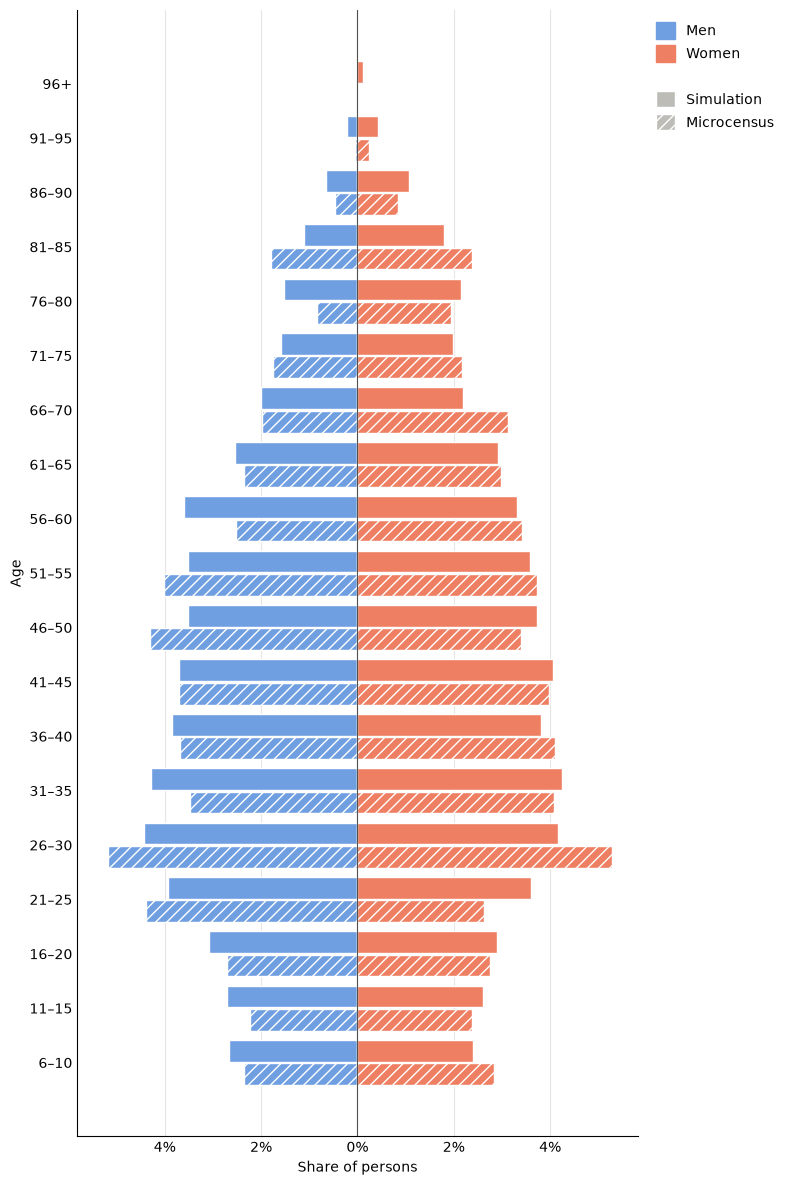

         sim            mz        diff_pp       
sex_    male female   male female    male female
6–10   2.674  2.408  2.358  2.836   0.316 -0.428
11–15  2.701  2.609  2.235  2.374   0.466  0.235
16–20  3.089  2.896  2.704  2.742   0.385  0.154
21–25  3.922  3.595  4.385  2.634  -0.464  0.962
26–30  4.434  4.160  5.170  5.286  -0.736 -1.126
31–35  4.291  4.242  3.472  4.074   0.819  0.168
36–40  3.839  3.812  3.675  4.108   0.164 -0.296
41–45  3.711  4.062  3.708  3.974   0.003  0.088
46–50  3.507  3.733  4.305  3.388  -0.798  0.345
51–55  3.507  3.574  4.012  3.725  -0.505 -0.151
56–60  3.604  3.311  2.511  3.426   1.094 -0.115
61–65  2.548  2.918  2.346  2.978   0.203 -0.061
66–70  1.996  2.188  1.971  3.133   0.025 -0.944
71–75  1.584  1.984  1.759  2.172  -0.175 -0.188
76–80  1.529  2.161  0.839  1.941   0.690  0.220
81–85  1.108  1.807  1.789  2.375  -0.681 -0.568
86–90  0.650  1.062  0.471  0.843   0.179  0.219
91–95  0.214  0.436  0.048  0.234   0.166  0.202
96+    0.027  0.107 

In [15]:
# %% 6. Population pyramid, share of all persons per age group and sex ---------------
plot_pyramid(sim_p, mz_p, 'age_pyramid.png')

ps, pm = pyramid_shares(sim_p) * 100, pyramid_shares(mz_p) * 100
pyramid = pd.concat({'sim': ps, 'mz': pm, 'diff_pp': ps - pm}, axis=1).round(3)
pyramid.index = [nice_label(i) for i in pyramid.index]
print(pyramid); pyramid.to_csv(OUT_DIR / 'age_pyramid_table.csv')

#### Age distribution in single years

        sim      mz  diff_pp  n_sim  n_mz
age                                      
6    0.0101  0.0055   0.4664    332    11
7    0.0101  0.0093   0.0768    330    23
8    0.0107  0.0123  -0.1613    350    24
9    0.0098  0.0119  -0.2030    322    28
10   0.0101  0.0130  -0.2907    331    30
11   0.0103  0.0113  -0.0968    337    26
12   0.0112  0.0079   0.3365    368    20
13   0.0104  0.0100   0.0432    342    25
14   0.0103  0.0089   0.1409    337    25
15   0.0109  0.0081   0.2778    356    24


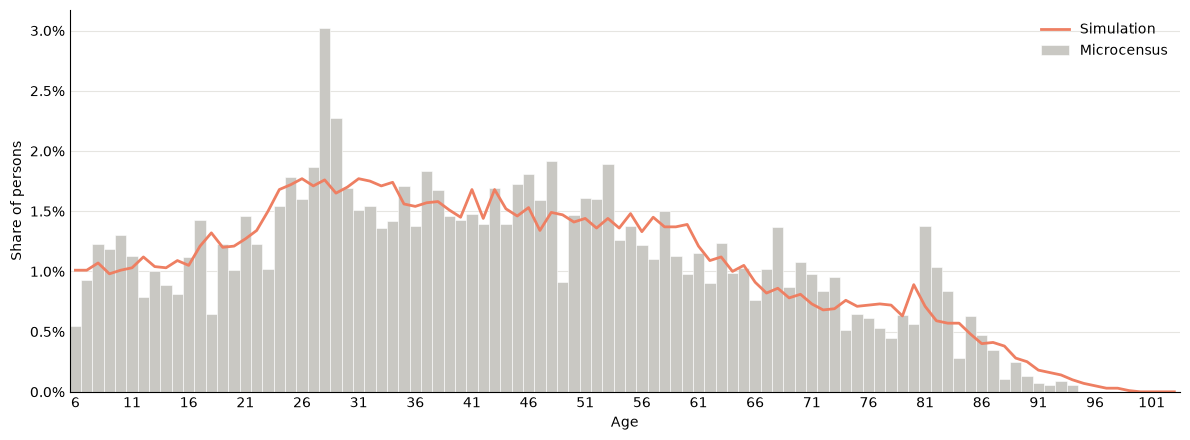

In [16]:
# %% 7. Age distribution, 1-year bins ---------------------------------------------
ages = list(range(MIN_AGE, int(max(sim_p['age_1y'].max(), mz_p['age_1y'].max())) + 1))
age_cmp = compare(sim_p, mz_p, 'age_1y', ages)
age_cmp.index.name = 'age'
print(age_cmp.head(10)); age_cmp.to_csv(OUT_DIR / 'age_distribution_1y_table.csv')
plot_age_profile(age_cmp['sim'], age_cmp['mz'], 'age_distribution_1y.png')

#### Driving licence

            sim      mz  diff_pp  n_sim  n_mz
licence                                      
yes      0.7035  0.6793   2.4283  23052  1313
no       0.2965  0.3207  -2.4283   9714   630


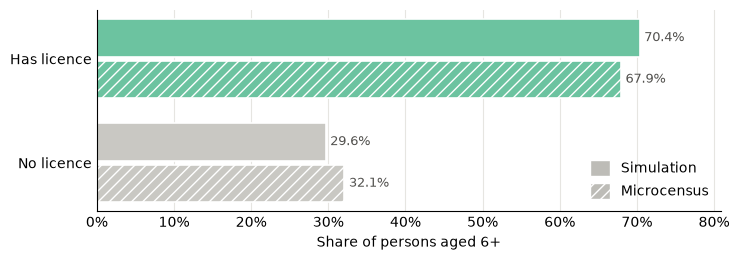

In [17]:
# %% 8. Driving licence -----------------------------------------------------------
LICENCE = ['yes', 'no']
licence_cmp = compare(sim_p, mz_p, 'licence', LICENCE)
print(licence_cmp); licence_cmp.to_csv(OUT_DIR / 'driving_licence_table.csv')
plot_total(sim_p, mz_p, 'licence', LICENCE, 'driving_licence.png',
           labels=dict(yes='Has licence', no='No licence'), colors=LICENCE_COLORS,
           xlabel=f'Share of persons aged {MIN_AGE}+')

#### Household location type (urban / suburban / rural)

             sim      mz  diff_pp  n_sim  n_mz
cat                                           
urban     0.9238  0.7399  18.3844  14768  1348
suburban  0.0762  0.2220 -14.5773   1219   489
rural     0.0000  0.0381  -3.8072      0   106


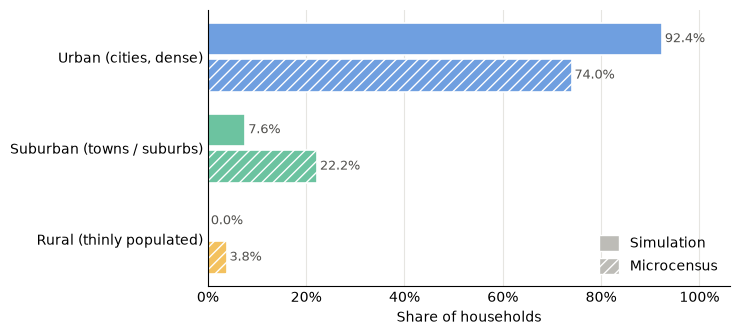

In [18]:
# %% 9. Household location type ---------------------------------------------------
present = set(sim_hh['cat']) | set(mz_hh['cat'])
hh_cats = [c for c in HH_CATS if c in present]
hh_cmp = compare(sim_hh, mz_hh, 'cat', hh_cats)
print(hh_cmp); hh_cmp.to_csv(OUT_DIR / 'household_urbanity_table.csv')
plot_total(sim_hh, mz_hh, 'cat', hh_cats, 'household_urbanity.png',
           labels=dict(urban='Urban (cities, dense)', suburban='Suburban (towns / suburbs)',
                       rural='Rural (thinly populated)', unknown='Unknown / missing'),
           colors=URBAN_COLORS, xlabel='Share of households')

#### Activity chains
Home-based tours written as letter strings, e.g. `HWH` = home - work - home. Persons without any tour count as `H`. Only basic activities (work, education, shop, leisure, other) and `Ou` = activity outside the study area. Shares are computed within each source (and within each sex).

MZ purpose codes (`wzweck1`): 1 change of mode / park car, 2 work, 3 education, 4 shopping, 5 errands / services, 6 business, 7 service trip, 8 leisure, 9 accompanying (children), 10 accompanying / service (others), 11 return home, 12 other, 13 border crossing.

In [19]:
# %% 10. Chain helpers (shared by simulation and MZ) -----------------------------
def merge_outside(chain):
    """Collapse consecutive 'Ou' stops into one: HOuOuOuH -> HOuH."""
    return re.sub(r'(?:Ou)+', 'Ou', chain)


def split_into_tours(codes):
    """Cut a sequence of letters at every 'H' into complete home-to-home tours; anything before
    the first or after the last H is discarded. ['H','W','H','S','L','H'] -> ['HWH','HSLH']"""
    tours, current, started = [], [], False
    for code in codes:
        if code == 'H':
            if started and current:
                tours.append('H' + ''.join(current) + 'H')
            current, started = [], True
        elif started:
            current.append(code)
    return tours


def plan_tours(seq, mode):
    """One daily letter sequence -> (tours, status); status 'home' (never leaves home),
    'excluded' (no usable tour), 'ok' or 'closed' (plan repaired according to `mode`)."""
    if all(c == 'H' for c in seq):
        return [], 'home'
    if 'H' not in seq:
        return [], 'excluded'
    if seq[0] == 'H' and seq[-1] == 'H':
        return split_into_tours(seq), 'ok'
    if mode == 'drop':
        tours = split_into_tours(seq)
        return tours, ('ok' if tours else 'excluded')
    if mode == 'cyclic':
        first_home = seq.index('H')
        seq = seq[first_home:] + seq[:first_home] + ['H']
    else:                                          # 'insert'
        if seq[0] != 'H':
            seq = ['H'] + seq
        if seq[-1] != 'H':
            seq = seq + ['H']
    return split_into_tours(seq), 'closed'


def to_letters(purposes, outside_flags):
    """MZ purpose codes -> chain letters. Home trips and unknown codes are dropped,
    trips ending outside the study area become 'Ou'."""
    letters = []
    for code, outside in zip(purposes, outside_flags):
        if code == MZ_HOME:
            continue
        letter = 'Ou' if outside else MZ_MAP.get(code)
        if letter:
            letters.append(letter)
    return letters


def person_tours(trips):
    """Tour strings of one MZ person from its ordered trips."""
    if USE_OUTINGS and 'ausnr' in trips.columns:
        tours = []
        for _, outing in trips.groupby('ausnr', sort=False):
            acts = to_letters(outing['wzweck1'].iloc[:-1], outing['outside'].iloc[:-1])   # last trip = back home
            if acts:
                tours.append(merge_outside('H' + ''.join(acts) + 'H'))
        return tours
    pairs = list(zip(trips['wzweck1'], trips['outside']))
    if COLLAPSE_RETURN_PAIRS:                      # one tour per day, consecutive duplicates merged
        kept = [p for i, p in enumerate(pairs) if i == 0 or p[0] != pairs[i - 1][0]]
        acts = to_letters(*zip(*kept)) if kept else []
        return [merge_outside('H' + ''.join(acts) + 'H')] if acts else []
    seq = ['H']                                    # split the day at every explicit home trip
    for code, out in pairs:
        if code == MZ_HOME:
            seq.append('H')
        else:
            seq.extend(to_letters([code], [out]))
    return [merge_outside(t) for t in split_into_tours(seq)]


def chain_order(sim, mz):
    """All chains, most frequent in the MZ first."""
    rank = mz.groupby('chain')['weight'].sum().sort_values(ascending=False)
    return list(rank.index) + [c for c in sim['chain'].unique() if c not in rank.index]

In [20]:
# %% 11. Chains: one row per tour -----------------------------------------------------
# simulation
seqs = (sim_acts.assign(letter=sim_acts['type'].map(MATSIM_MAP)).dropna(subset=['letter'])
        .groupby('person', sort=False)['letter'].agg(list))
rows, status = [], Counter()
for pid, sex, has_leg in zip(sim_p['person'], sim_p['sex_'], sim_p['has_leg']):
    tours, st = plan_tours(seqs.get(pid, []), CLOSE_MODE) if has_leg else ([], 'home')
    status[st] += 1
    if tours:
        rows += [(pid, sex, merge_outside(t)) for t in tours]
    elif st == 'home':
        rows.append((pid, sex, 'H'))               # 'excluded' persons are not counted
sim_chains = pd.DataFrame(rows, columns=['person', 'sex_', 'chain'])
sim_chains['weight'] = 1.0
print('Simulation plan status:', dict(status))

# Microcensus (weighted with the person weight)
rows = [(hh, t) for hh, g in mz_t.groupby('HHNR') for t in person_tours(g)]
mz_chains = pd.DataFrame(rows, columns=['HHNR', 'chain']).merge(mz_pw[['HHNR', 'sex_', 'weight']], on='HHNR')
stay = mz_pw[~mz_pw['HHNR'].isin(mz_chains['HHNR'])][['HHNR', 'sex_', 'weight']].assign(chain='H')
mz_chains = pd.concat([mz_chains, stay], ignore_index=True)
print(f'MZ: {len(stay):,} weekday persons without any tour (counted as H)')
print(f'tours: simulation {len(sim_chains):,}, MZ {len(mz_chains):,} (unweighted)')

Simulation plan status: {'ok': 27528, 'excluded': 1588, 'home': 3650}
MZ: 124 weekday persons without any tour (counted as H)
tours: simulation 46,877, MZ 2,003 (unweighted)


          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1475  0.1398   0.7746   6915   283
HWH    0.1291  0.1245   0.4522   6050   228
HOuH   0.1037  0.0938   0.9826   4859   190
HSH    0.0977  0.0906   0.7085   4581   180
HOH    0.0747  0.0890  -1.4305   3500   179
HEH    0.0891  0.0794   0.9683   4175   186
H      0.0779  0.0601   1.7741   3650   124
HLLH   0.0132  0.0169  -0.3726    618    38
HOLH   0.0077  0.0150  -0.7307    362    29
HWSH   0.0116  0.0138  -0.2191    543    25
HOSH   0.0137  0.0116   0.2129    644    23
HSLH   0.0103  0.0115  -0.1114    485    24
HOuSH  0.0061  0.0114  -0.5282    286    19
HWLWH  0.0092  0.0091   0.0121    433    16
HLSH   0.0105  0.0083   0.2217    493    18
HWLH   0.0086  0.0078   0.0750    402    15
HSOH   0.0052  0.0064  -0.1177    243    12
HOuOH  0.0034  0.0054  -0.2021    158    11
HOWH   0.0047  0.0049  -0.0260    218     9
HOuLH  0.0060  0.0046   0.1414    280     8


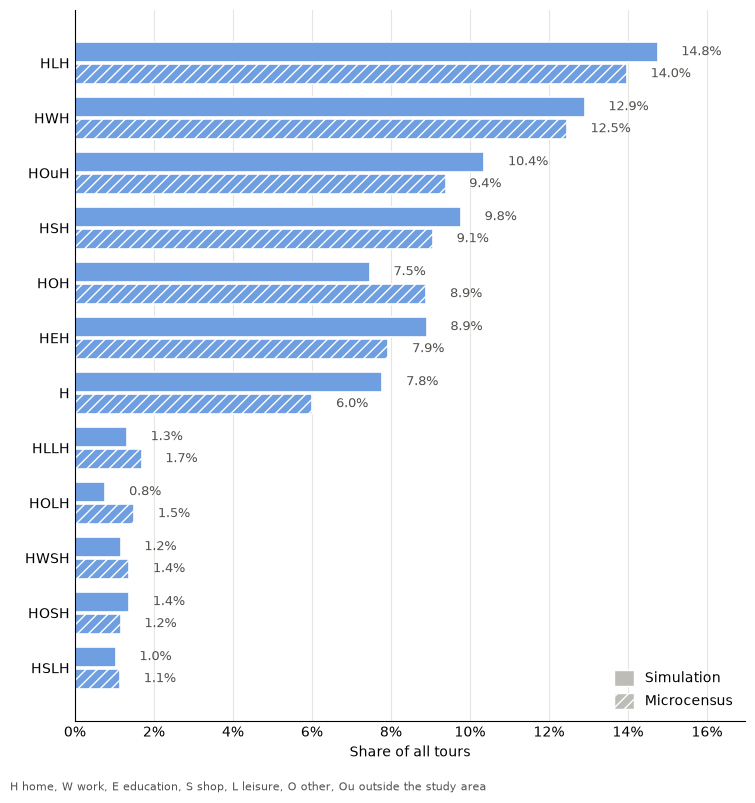

In [21]:
# %% 12. Chain shares, all persons ------------------------------------------------------
CHAIN_NOTE = 'H home, W work, E education, S shop, L leisure, O other, Ou outside the study area'

chains_all = chain_order(sim_chains, mz_chains)
chain_cmp = compare(sim_chains, mz_chains, 'chain', chains_all)
chain_cmp.index.name = 'chain'
print(chain_cmp.head(20)); chain_cmp.to_csv(OUT_DIR / 'chains_total.csv')

top = chains_all[:TOP_N_CHAINS]
plot_total(sim_chains, mz_chains, 'chain', top, 'chains_top.png',
           labels={c: c for c in top}, colors={c: COLORS['pt'] for c in top},
           xlabel='Share of all tours', footnote=CHAIN_NOTE)


--- Male ---
           sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1539  0.1457   0.8163   3544   129
HWH    0.1493  0.1362   1.3133   3440   113
HOuH   0.1178  0.1182  -0.0381   2713   103
HEH    0.0930  0.0949  -0.1867   2142    99
HSH    0.0812  0.0711   1.0163   1871    60
HOH    0.0639  0.0595   0.4384   1471    54
H      0.0624  0.0553   0.7091   1438    50
HLLH   0.0146  0.0184  -0.3765    336    18
HOLH   0.0073  0.0128  -0.5445    169    10
HSLH   0.0107  0.0108  -0.0100    246    11
HWSH   0.0085  0.0098  -0.1296    196     7
HOSH   0.0091  0.0088   0.0313    209     7
HWLH   0.0118  0.0082   0.3592    272     5
HWLWH  0.0109  0.0081   0.2792    250     7
HOuSH  0.0049  0.0078  -0.2939    113     7

--- Female ---
           sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1414  0.1348   0.6590   3371   154
HWH    0.1095  0.1147  -0.5281   2610   115
HOH    0.0851  0.1137  -2.8613   2029   125


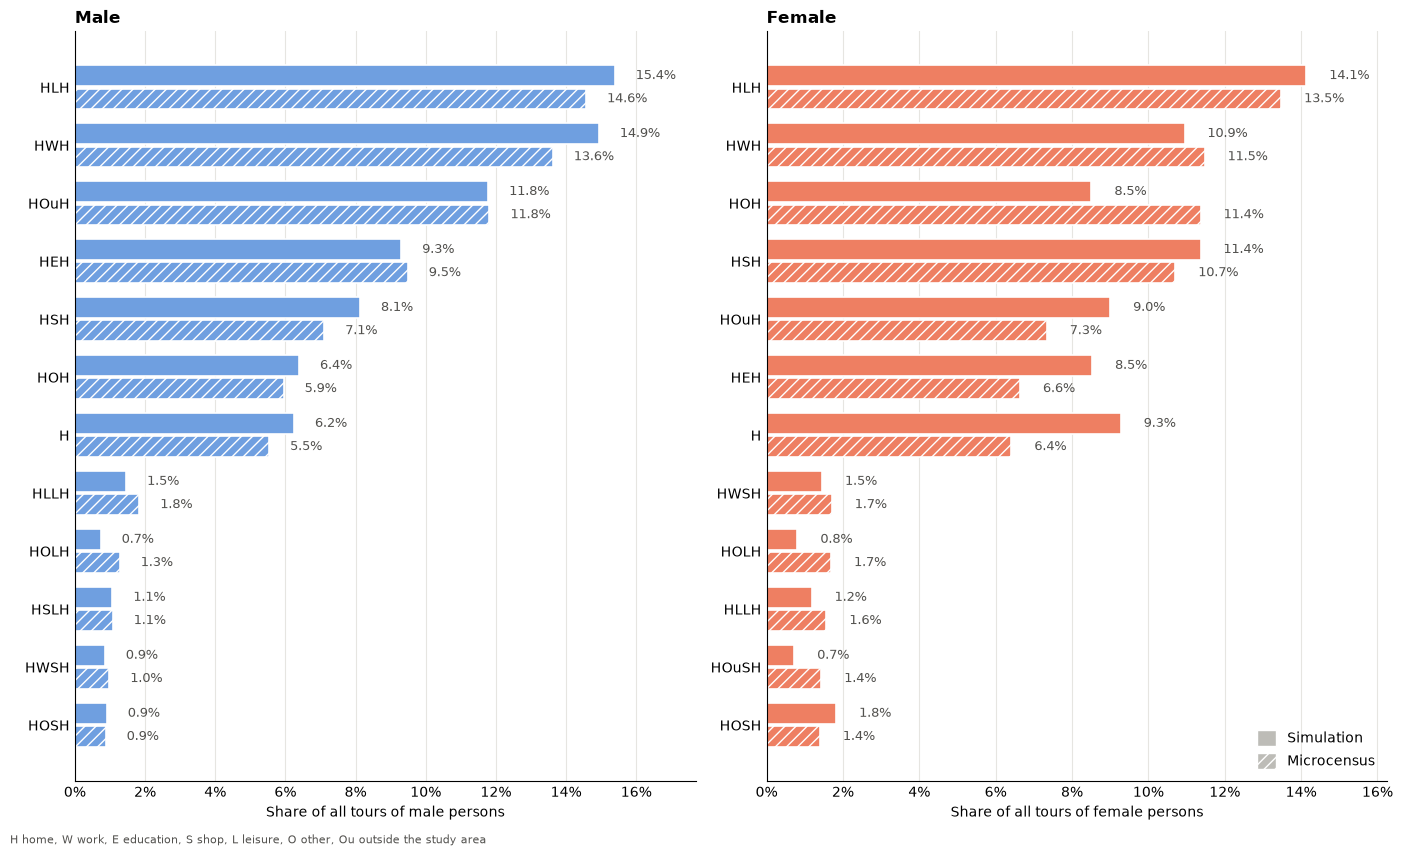

In [22]:
# %% 13. Chain shares by sex ------------------------------------------------------------
SEXES = ['male', 'female']
per_sex = {}
for sex in SEXES:
    sim_s, mz_s = sim_chains[sim_chains['sex_'] == sex], mz_chains[mz_chains['sex_'] == sex]
    order = chain_order(sim_s, mz_s)
    per_sex[sex] = (sim_s, mz_s, order)
    res = compare(sim_s, mz_s, 'chain', order)
    res.index.name = 'chain'
    print(f'\n--- {nice_label(sex)} ---\n', res.head(15)); res.to_csv(OUT_DIR / f'chains_{sex}.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 0.55 * TOP_N_CHAINS + 1.8))
for ax, sex in zip(axes, SEXES):
    sim_s, mz_s, order = per_sex[sex]
    cats = order[:TOP_N_CHAINS]
    draw_total(ax, shares(sim_s, 'chain', cats), shares(mz_s, 'chain', cats), cats,
               labels={c: c for c in cats}, colors={c: SEX_COLORS[sex] for c in cats})
    ax.set_title(nice_label(sex), loc='left', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'Share of all tours of {sex} persons')
axes[1].legend(handles=src_legend(), frameon=False, loc='lower right', handlelength=1.4, handleheight=1.4)
fig.text(0.0, -0.01, CHAIN_NOTE, fontsize=8, color=TEXT_COLOR)
fig.tight_layout()
fig.savefig(OUT_DIR / 'chains_by_sex.png', dpi=200, bbox_inches='tight')
plt.show()

#### Destination maps

destinations inside the area: simulation 51,916, MZ 3,965 (unweighted)


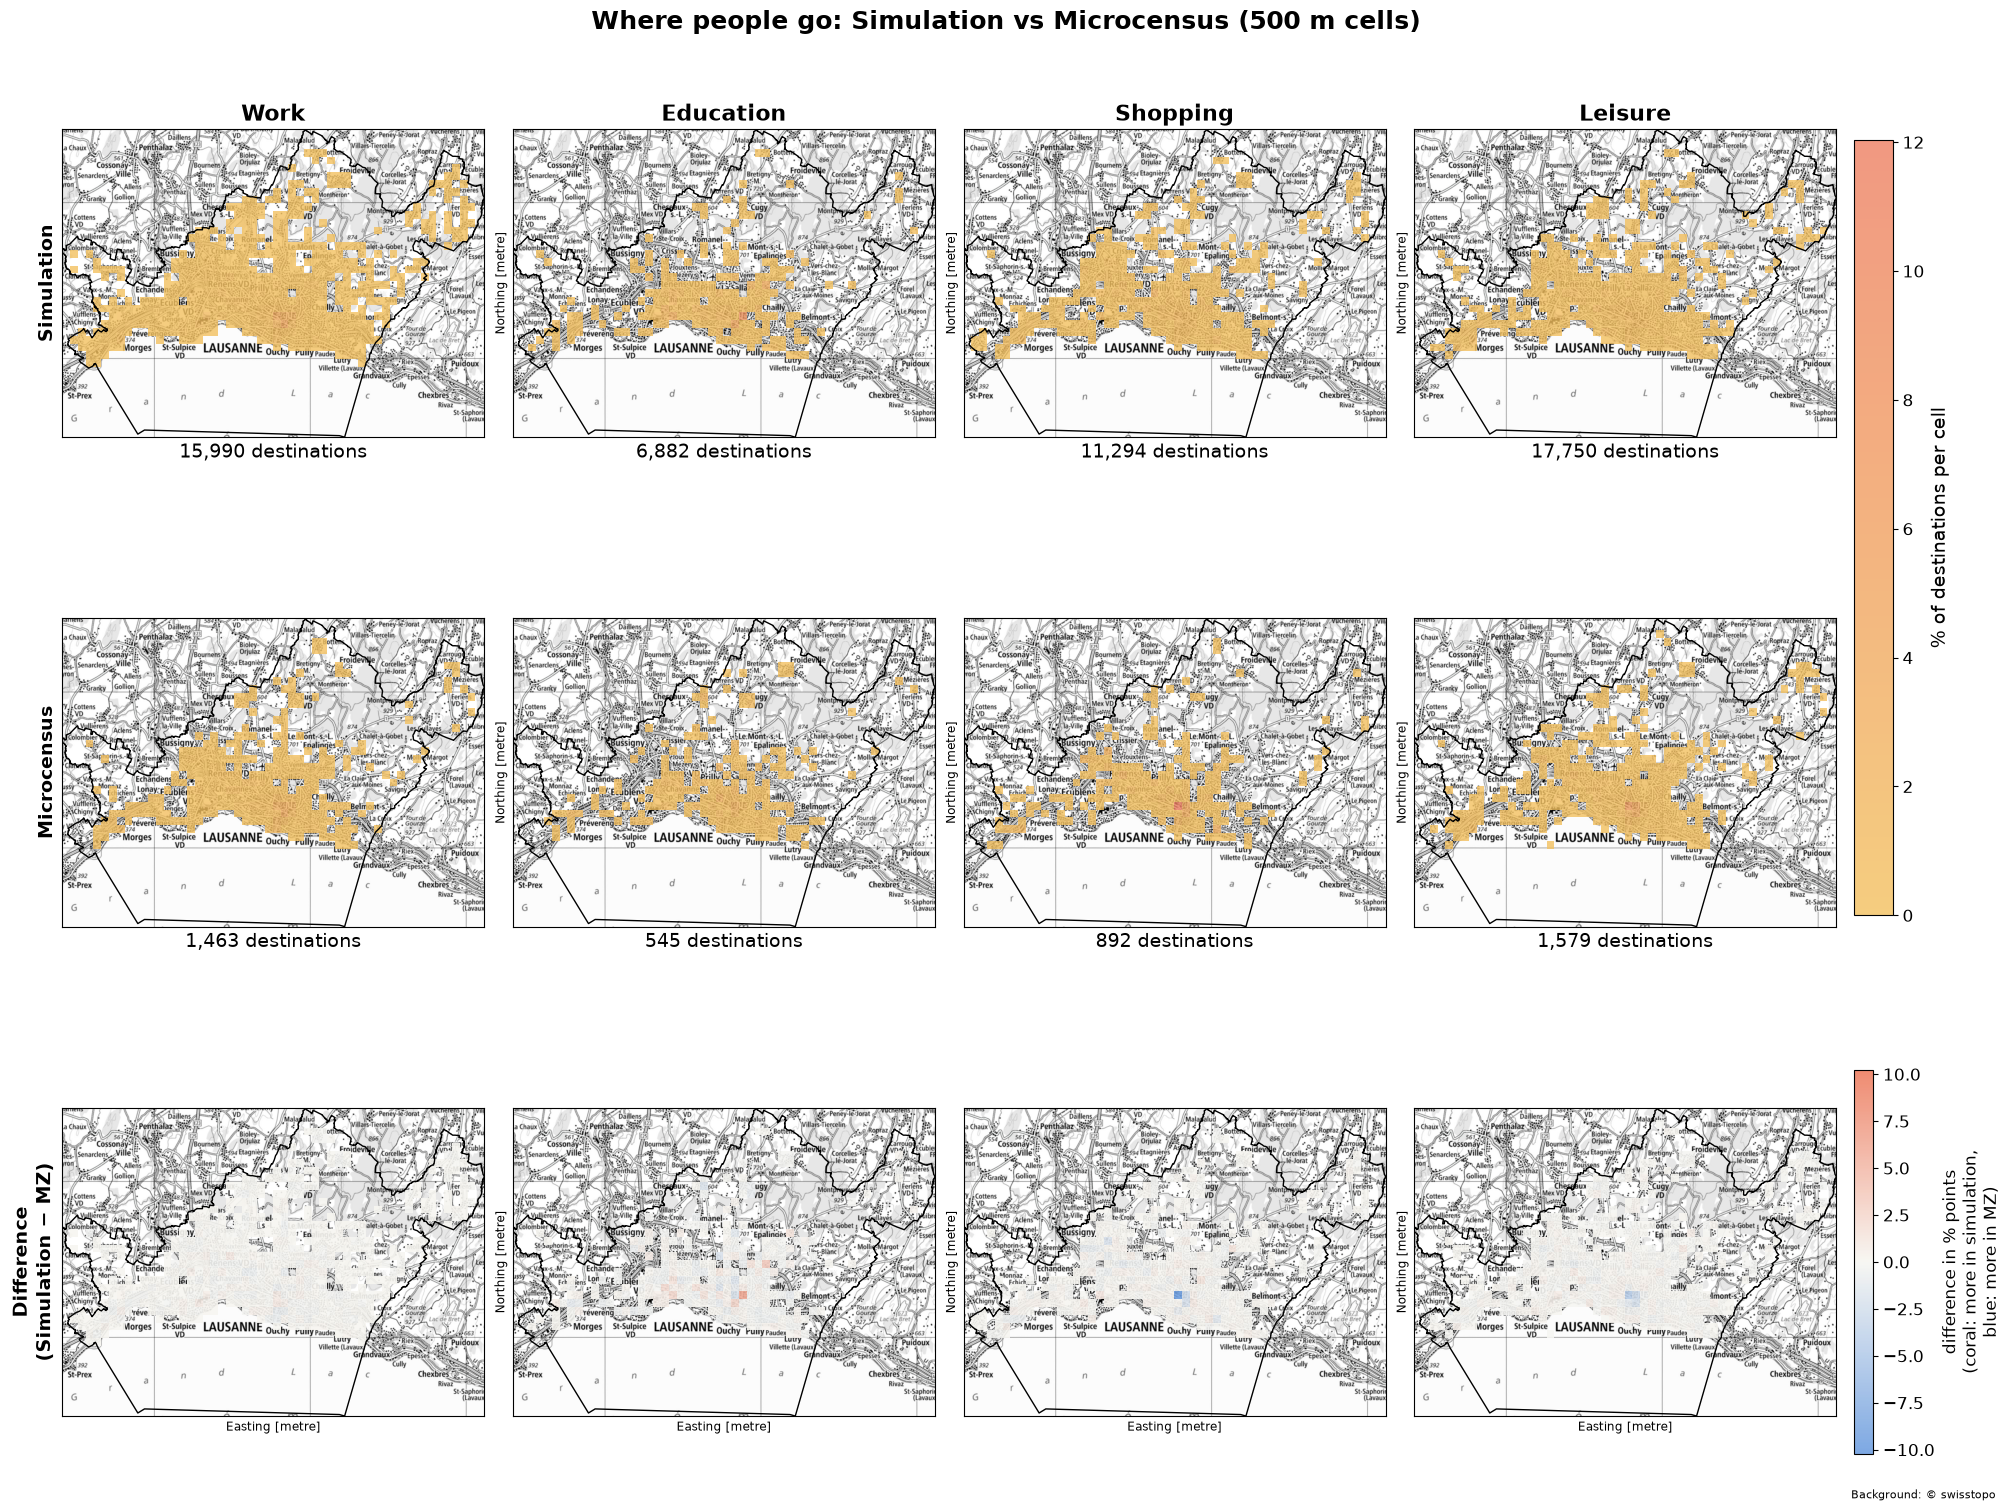

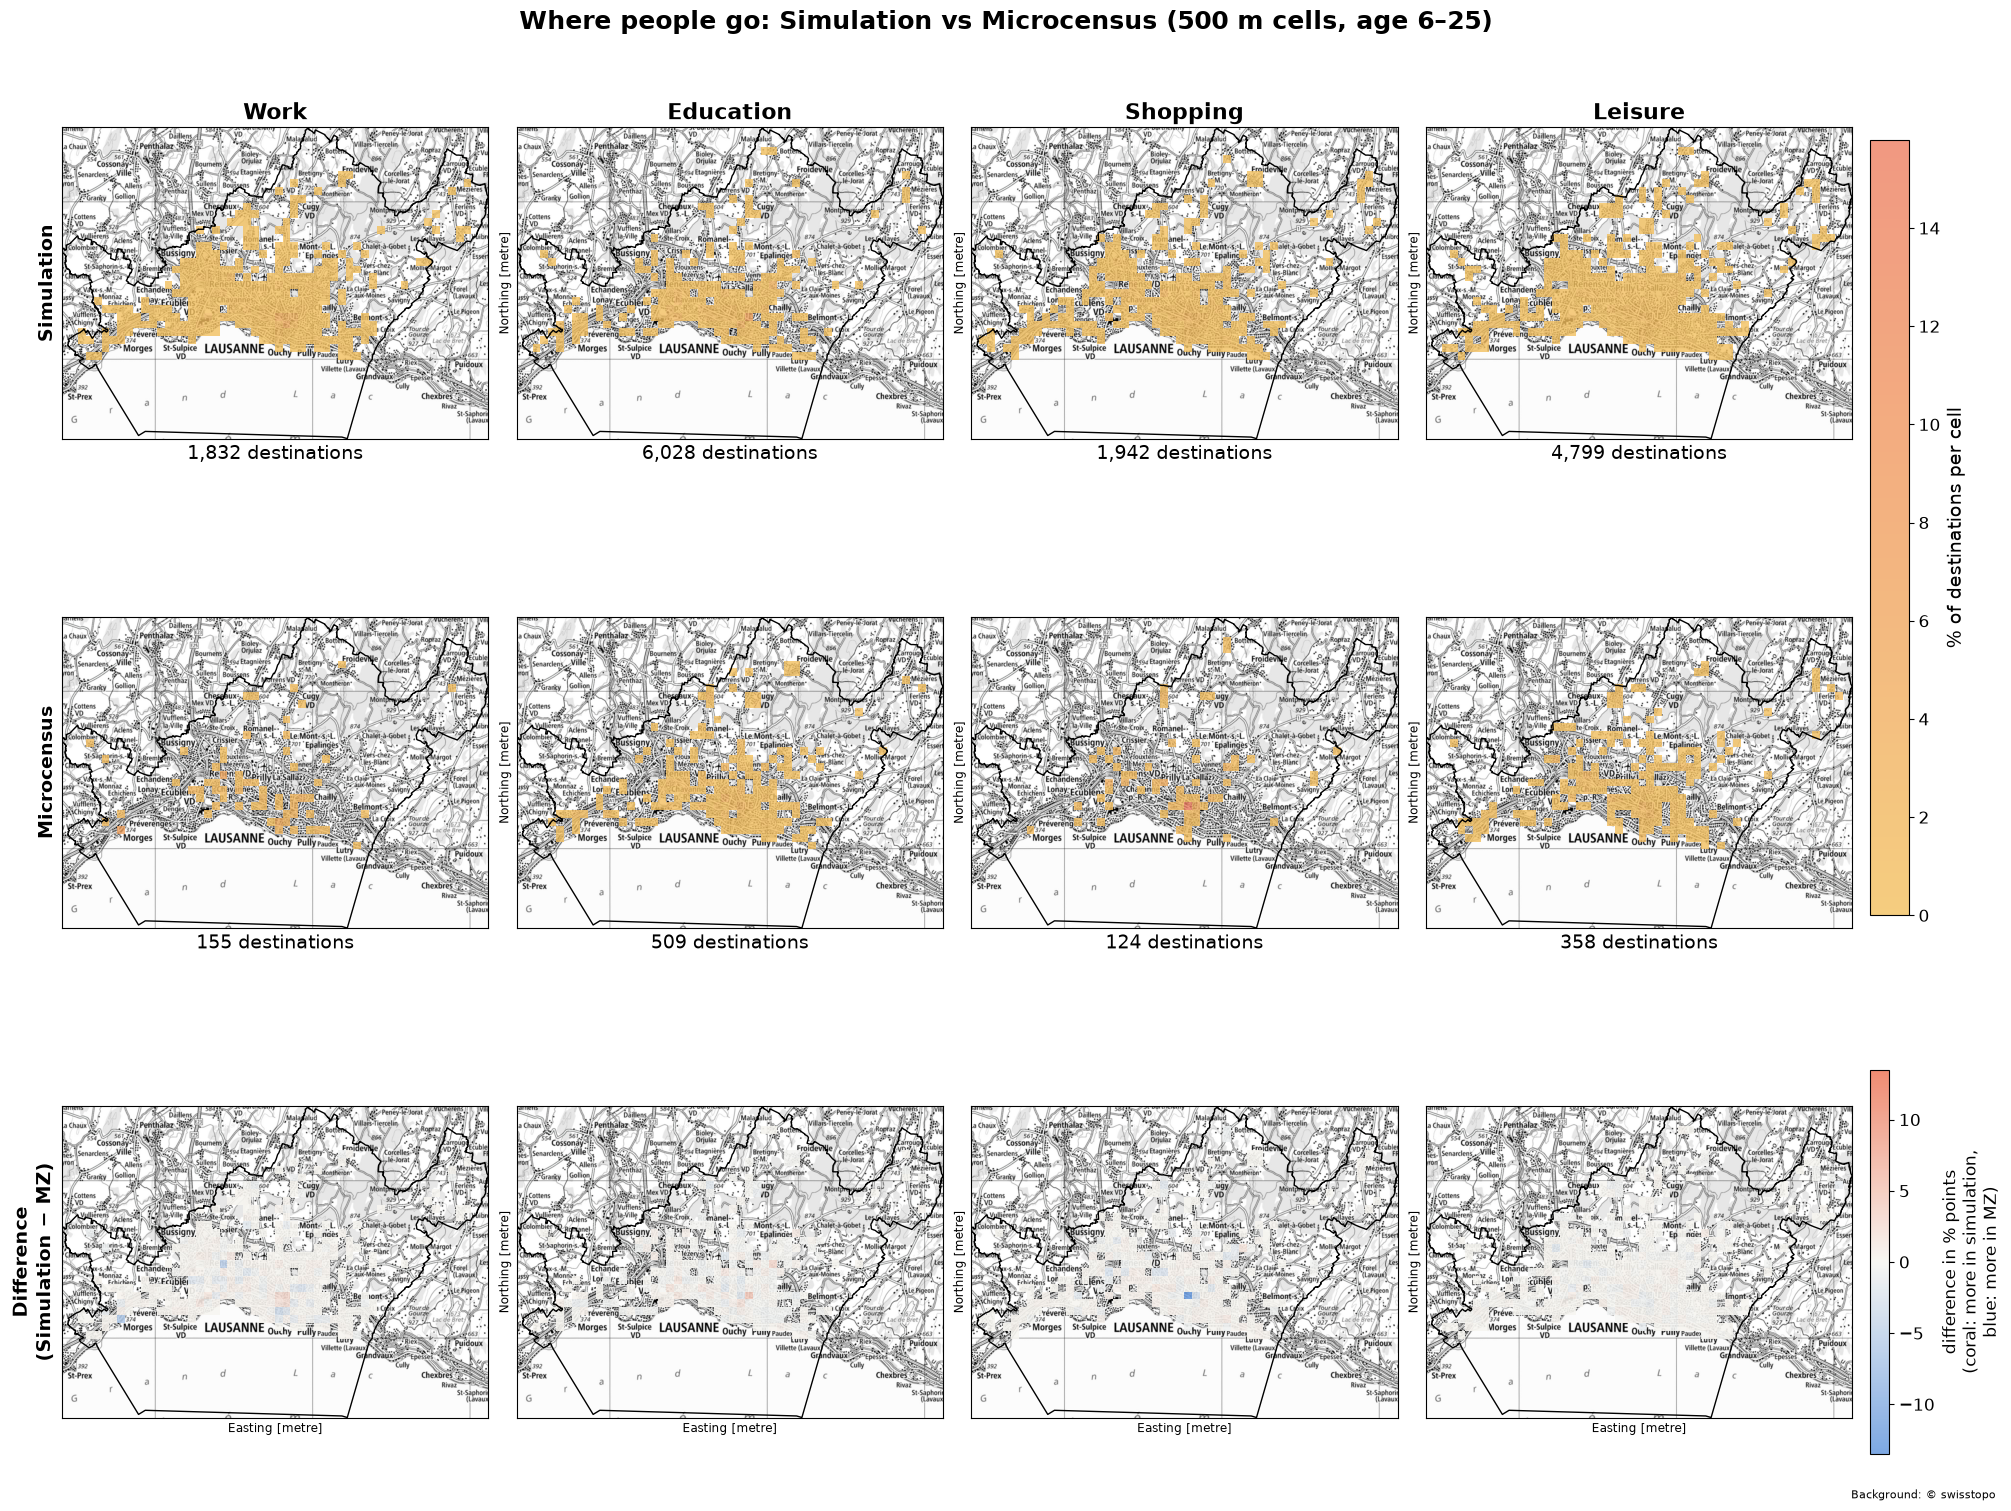

In [13]:
# %% 14. Destinations of work / education / shopping / leisure inside the study area ---
# simulation: all such activities of agents aged MIN_AGE+
sim_d = sim_acts.merge(sim_p[['person', 'age']], on='person')
sim_d['purpose'] = sim_d['type'].map(MATSIM_MAP)
sim_d = sim_d[sim_d['purpose'].isin(MAP_PURPOSES) & sim_d[['x', 'y']].notna().all(axis=1)]
sim_d = sim_d[inside(sim_d['x'], sim_d['y'])].assign(w=1.0)[['purpose', 'x', 'y', 'w', 'age']]

# Microcensus: weekday trips ending inside the study area
mz_d = mz_t[mz_t['letter'].isin(MAP_PURPOSES) & mz_t['dest_in']]
mz_d = mz_d.rename(columns={'letter': 'purpose', 'dx': 'x', 'dy': 'y', 'weight': 'w'})[['purpose', 'x', 'y', 'w', 'age']]
print(f'destinations inside the area: simulation {len(sim_d):,}, MZ {len(mz_d):,} (unweighted)')


def plot_destination_maps(sim_d, mz_d, cell_m, age_range, fname):
    """Rows: simulation, Microcensus, difference. Columns: purposes. Each cell shows the % of that
    purpose's destinations in each grid cell, so the sources are comparable despite different sizes.
    Colour scales are shared: one for rows 1-2 (all purposes), one for the difference row."""
    lo, hi = age_range
    def select(df):
        keep = np.ones(len(df), dtype=bool)
        if lo is not None: keep &= (df['age'] >= lo).to_numpy()
        if hi is not None: keep &= (df['age'] <= hi).to_numpy()
        return df[keep]
    sources = {'Simulation': select(sim_d), 'Microcensus': select(mz_d)}

    minx, miny, maxx, maxy = area.total_bounds
    xedges = np.arange(minx, maxx + cell_m, cell_m)
    yedges = np.arange(miny, maxy + cell_m, cell_m)

    def decorate(ax):
        area.boundary.plot(ax=ax, color='black', linewidth=1)
        ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
        try:                                       # swisstopo tiles need internet access
            ctx.add_basemap(ax, source=SWISSTOPO_TILES, crs=area.crs, zoom=MAP_ZOOM, attribution=False)
        except Exception as e:
            print('basemap not available:', type(e).__name__)
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])

    # --- 1) compute all grids first, so scales can be shared across purposes ---
    grids, totals, diffs = {}, {}, {}
    for code in MAP_PURPOSES:
        for src, df in sources.items():
            d = df[df['purpose'] == code]
            h, _, _ = np.histogram2d(d['x'], d['y'], bins=[xedges, yedges], weights=d['w'])
            totals[code, src] = h.sum()
            grids[code, src] = 100 * h / h.sum() if h.sum() > 0 else h
        diffs[code] = grids[code, 'Simulation'] - grids[code, 'Microcensus']   # percentage points

    vmax = max(g.max() for g in grids.values()) or 1.0          # one scale for rows 1-2
    lim = max(np.abs(d).max() for d in diffs.values()) or 1.0   # one symmetric scale for row 3

    # --- 2) plot ---
    fig, axes = plt.subplots(3, len(MAP_PURPOSES), figsize=(20, 15), layout='constrained')
    mesh = dmesh = None
    for j, (code, name) in enumerate(MAP_PURPOSES.items()):
        for i, src in enumerate(sources):
            ax = axes[i, j]
            mesh = ax.pcolormesh(xedges, yedges, np.ma.masked_equal(grids[code, src].T, 0),
                                 cmap=SEQ_CMAP, vmin=0, vmax=vmax, alpha=0.8)
            decorate(ax)
            ax.set_xlabel(f'{totals[code, src]:,.0f} destinations', fontsize=14)
            if i == 0: ax.set_title(name, fontsize=16, fontweight='bold')
            if j == 0: ax.set_ylabel(src, fontsize=14, fontweight='bold')

        ax = axes[2, j]
        dmesh = ax.pcolormesh(xedges, yedges, np.ma.masked_equal(diffs[code].T, 0),
                              cmap=DIV_CMAP, vmin=-lim, vmax=lim, alpha=0.9)
        decorate(ax)
        if j == 0: ax.set_ylabel('Difference\n(Simulation − MZ)', fontsize=14, fontweight='bold')

    # --- 3) two shared colourbars on the right ---
    cbar = fig.colorbar(mesh, ax=axes[:2, :], location='right', shrink=0.8, pad=0.01,
                        label='% of destinations per cell')
    cbar.ax.yaxis.label.set_size(14); cbar.ax.tick_params(labelsize=12)

    cbar = fig.colorbar(dmesh, ax=axes[2, :], location='right', shrink=0.8, pad=0.01,
                        label='difference in % points\n(coral: more in simulation,\nblue: more in MZ)')
    cbar.ax.yaxis.label.set_size(12); cbar.ax.tick_params(labelsize=12)

    age_label = f', age {lo}–{hi}' if lo is not None or hi is not None else ''
    fig.suptitle(f'Where people go: Simulation vs Microcensus ({cell_m} m cells{age_label})',
                 fontsize=18, fontweight='bold')
    fig.text(0.995, 0.005, 'Background: \u00a9 swisstopo', ha='right', fontsize=8)
    fig.savefig(OUT_DIR / fname, dpi=200)
    plt.show()


for run in MAP_RUNS:
    lo, hi = run['age_range']
    tag = 'all_ages' if lo is None and hi is None else f'age{lo}-{hi}'
    plot_destination_maps(sim_d, mz_d, run['cell_m'], run['age_range'], f'destination_maps_{tag}_{run["cell_m"]}m.png')